<img src="logo.png" alt="Vegeta" width="240">

# X-wing — Kestrel's motors, battery and pod on four cantilever panels, no bracing

The biplane of notebook 38 carries its four rotors on two wings joined by a truss. The **X-wing** carries the same
four rotors, the same battery and the same pod on **four straight cantilever panels radiating at ±45°** — seen as
wings, two straight wings of equal span crossing at the pod, one rolled +45° and one −45°. There is no truss to weigh,
to fair or to brace; the aircraft stands on its four tips. The question: with everything bought held equal, does the
X beat the braced biplane — and what does the 45° cost?

The geometry decides a lot before any analysis: a panel's lift is normal to the panel, so only cos 45° of it is
vertical, and the panel sees only cos 45° of the aircraft's angle of attack. The vertical lift slope of four panels is
about half that of the same area laid flat. Two variants: **X-A** with the biplane's wing area (4 × 0.50 m × 0.14 m) and
**X-B** with twice it (4 × 0.70 m × 0.20 m).

```
layout (kestrel_xwing) ─► clearances, the motors' stations (pitch and yaw levers equal), projected span
masses: the biplane's parts without the truss and the fin, the spars sized as cantilevers (stress, deflection, first mode)
hold point: the allocation matrix on the X's stations (kestrel_control with L=)
lattice (peregrine_flight.vlm) on four panels at 45° ─► vertical lift slope, induced drag, neutral point
drag build-up (no struts), cruise with the pitch trimmed by the rotors' vertical lever, stance on the tips
transitions in notebook 38's panel model (each panel at its dihedral, blown by its own rotor): the matrix, the strategies
against Kestrel-4Q and Kestrel-4Q-2 (designs/data/kestrel_design.json)
```
Modules: `designs/kestrel_xwing.py` (new), `kestrel_transition.py` (the panel model), `kestrel_control.py`,
`kestrel_systems.py`, `kestrel_drawings.py`. **Status: concept study**, the same assumptions as notebook 38.

In [1]:
DEBUG = False
from vegeta import mock
DEBUG = mock.setup(DEBUG)

In [2]:
import json, math, os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
sys.path.insert(0, "designs")
import kestrel, kestrel_systems as ks, kestrel_control as kc, kestrel_flight as kf, kestrel_transition as kt, kestrel_xwing as kx, kestrel_drawings as kd

pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 220)
OUT = Path("output/39_xwing"); OUT.mkdir(parents=True, exist_ok=True)
QUICK = os.environ.get("XWING_QUICK") == "1"
KD = json.loads(Path("designs/data/kestrel_design.json").read_text()) if Path("designs/data/kestrel_design.json").exists() else None
print("Kestrel's design record:", "found" if KD else "missing (run notebook 38 first for the comparison rows)")
display(pd.DataFrame({v: p for v, p in kx.VARIANTS.items()}).T)

Kestrel's design record: found


,panel_length,chord,motor_r
X-A (the biplane's wing area),0.5,0.14,0.46
X-B (twice the wing area),0.7,0.20,0.66


## 1. The two X-wings

The layout, its rules (the discs clear each other, the pod and the tips) and the front views. The motors sit at 45°:
the pitch lever (their height) equals the yaw lever (their spanwise station) — 0.33 m for X-A against the biplane's
0.14 m pitch and 0.39 m yaw levers.

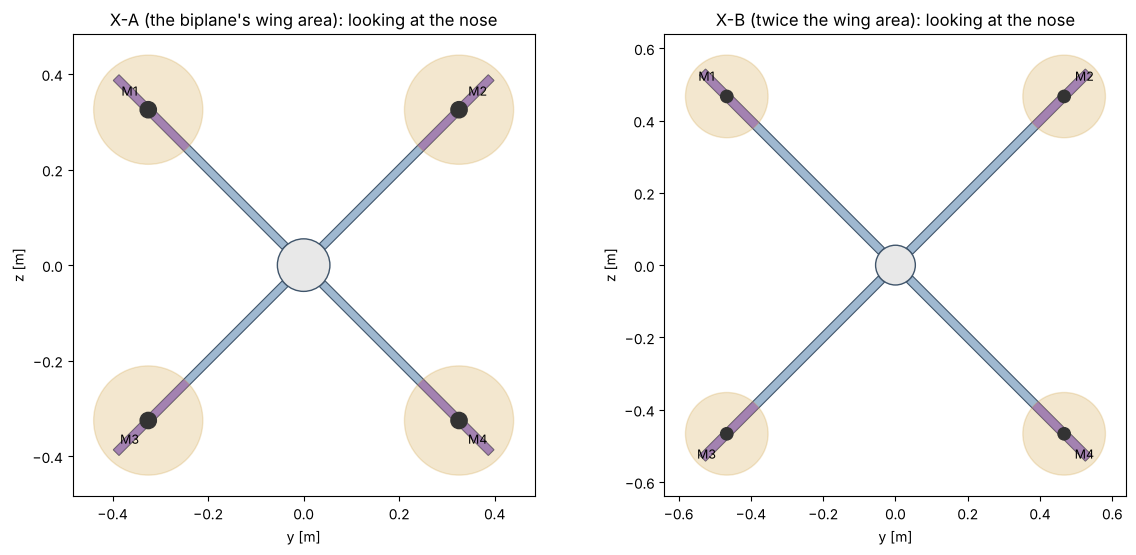

,panel_length,chord,motor_r,span,span_projected,height,S_ref,AR_wing,h,motor_y,prop_gap,prop_to_pod,prop_beyond_tip,elevon_y_in,elevon_span_side
X-A (the biplane's wing area),0.5,0.14,0.46,1.11,0.785,0.785,0.28,7.929,0.325,0.46,0.422,0.291,0.019,0.346,0.209
X-B (twice the wing area),0.7,0.20,0.66,1.51,1.068,1.068,0.56,7.550,0.467,0.66,0.705,0.491,0.019,0.546,0.209


{"X-A (the biplane's wing area)": 'all rules hold', 'X-B (twice the wing area)': 'all rules hold'}


In [3]:
XL = {v: kx.layout(v) for v in kx.VARIANTS}
fig, axs = plt.subplots(1, 2, figsize=(14, 6))
for ax_, (v, L) in zip(axs, XL.items()):
    kd.xwing_front_view(L, ax=ax_)
plt.show()
LAY = pd.DataFrame({v: {k: L[k] for k in ("panel_length", "chord", "motor_r", "span", "span_projected", "height", "S_ref", "AR_wing", "h", "motor_y",
                                           "prop_gap", "prop_to_pod", "prop_beyond_tip", "elevon_y_in", "elevon_span_side")} for v, L in XL.items()}).T
display(LAY.round(3))
print({v: kx.checks(L) or "all rules hold" for v, L in XL.items()})

## 2. Masses and the spars

The biplane's parts list without the truss and the fin plate (the panels are the fins); each panel's spar sized as a
cantilever with a tip motor at a 4 g pull-up — on stress (≤ 200 MPa), deflection (≤ 3 % of the length) and the first
bending mode of the motor on its arm (≥ 12 Hz, an octave above the pitch loop); the elevon servos; the feet at the
tips. The battery placed for the same CG rule as Kestrel's.

In [4]:
XT = {v: kx.mass_table(L) for v, L in XL.items()}
XCI = {v: ks.cg_inertia(t) for v, t in XT.items()}
MASS = pd.DataFrame({v: ks.groups(t) for v, t in XT.items()})
if KD:
    MASS["Kestrel-4Q"] = pd.Series({"propulsion": 0.736, "structure": None, "systems": None, "payload": None, "margin": None})
display(MASS.round(3))
display(pd.DataFrame({v: {"take-off mass [kg]": c["mass_kg"], "CG x [mm]": c["x_cg"] * 1000, "battery x [mm]": c["battery_x"] * 1000, "clipped": c["battery_clipped"],
                          "Ixx": c["Ixx"], "Iyy": c["Iyy"], "Izz": c["Izz"]} for v, c in XCI.items()}).T.round(4))
SPAR = pd.DataFrame({v: kx.cantilever(L, mass_kg=XCI[v]["mass_kg"]) for v, L in XL.items()}).T
display(SPAR)
print("Kestrel-4Q (Part I):", f"{KD['mass']['mass_kg']:.3f} kg" if KD else "—")

,X-A (the biplane's wing area),X-B (twice the wing area),Kestrel-4Q
propulsion,0.736,0.736,0.736
structure,0.478,0.769,NaN
systems,0.208,0.208,NaN
payload,0.105,0.105,NaN
margin,0.060,0.060,NaN


,take-off mass [kg],CG x [mm],battery x [mm],clipped,Ixx,Iyy,Izz
X-A (the biplane's wing area),1.587391,214.0,265.017328,False,0.128904,0.070148,0.070023
X-B (twice the wing area),1.877831,220.0,215.396511,False,0.305584,0.160009,0.159882


,n,panel lift [N],root moment [N·m],spar OD [mm],spar stress [MPa],spar reserve,tip deflection [mm],tip deflection / length,"first bending, with the tip motor [Hz]",spar mass per panel [g],sized by
X-A (the biplane's wing area),4.0,22.015052,2.311082,9.0,50.92895,7.854079,10.278894,0.020558,12.315989,19.477874,first mode
X-B (twice the wing area),4.0,26.043076,3.491622,13.5,30.53307,13.10055,9.228713,0.013184,12.260363,42.60785,first mode


Kestrel-4Q (Part I): 1.686 kg


## 3. The hold point

The same allocation matrix on the X's stations: the senses of rotation, the attainable moments, a motor out.

In [5]:
DR = ks.drive_table()
for v, L in XL.items():
    ci = XCI[v]
    print(v)
    display(kc.rank_table(kappa=float(DR.kap(0.0)), cg=ci, L=L)[["senses (M1..M4)", "rank", "condition", "verdict"]])
    display(kc.hover_authority(mass_kg=ci["mass_kg"], cg=ci, inertia=ci["I"], L=L).round(3))

X-A (the biplane's wing area)


,senses (M1..M4),rank,condition,verdict
"diagonal pairs (M1, M4 | M2, M3)","(1, -1, -1, 1)",4,61.906918,full control (thrust + 3 moments)
"side columns alike (M1, M3 | M2, M4)","(1, -1, 1, -1)",3,inf,NOT controllable in the hover
"rows alike (M1, M2 | M3, M4)","(1, 1, -1, -1)",3,inf,NOT controllable in the hover
all the same way,"(1, 1, 1, 1)",3,inf,NOT controllable in the hover


,most negative [N·m],most positive [N·m],inertia [kg·m²],angular acceleration [rad/s²]
about the thrust axis (hover heading / cruise roll),-0.233,0.233,0.129,1.811
about y (pitch-over / cruise pitch),-4.700,4.776,0.070,67.000
about z (hover tilt sideways / cruise yaw),-4.700,4.700,0.070,67.120


X-B (twice the wing area)


,senses (M1..M4),rank,condition,verdict
"diagonal pairs (M1, M4 | M2, M3)","(1, -1, -1, 1)",4,61.90688,full control (thrust + 3 moments)
"side columns alike (M1, M3 | M2, M4)","(1, -1, 1, -1)",3,inf,NOT controllable in the hover
"rows alike (M1, M2 | M3, M4)","(1, 1, -1, -1)",3,inf,NOT controllable in the hover
all the same way,"(1, 1, 1, 1)",3,inf,NOT controllable in the hover


,most negative [N·m],most positive [N·m],inertia [kg·m²],angular acceleration [rad/s²]
about the thrust axis (hover heading / cruise roll),-0.280,0.280,0.306,0.916
about y (pitch-over / cruise pitch),-8.089,8.166,0.160,50.555
about z (hover tilt sideways / cruise yaw),-8.089,8.089,0.160,50.595


## 4. Aerodynamics: the lattice at 45°, the drag, the cruise

The vortex lattice on the four panels as quads at ±45°: the vertical lift slope on the wing area (against the flat
biplane's), the induced-drag factor on the projected span, the neutral point. The drag build-up has no struts. The
cruise: the vertical CL the weight needs, the panels' own lift coefficient (CL / cos 45°), the angle of attack, the
power with the pitch trimmed by the rotors' vertical lever.

,CLα vertical [1/rad],CLα / the biplane's,induced k,e (projected span),AR projected,x_np [mm],Cd0,CdA [cm²]
X-A (the biplane's wing area),1.8791,0.4607,0.1453,0.9956,2.2002,232.7500,0.0344,96.3520
X-B (twice the wing area),1.8839,0.4619,0.1439,1.0868,2.0358,246.7969,0.0303,169.7934


,panels (4) [cm²],pod [cm²],nacelles (4) [cm²],"foot rods (4), axial [cm²]",camera dome [cm²],"wing-pod junctions (4, acute) [cm²]"
X-A (the biplane's wing area),24.5,4.3,6.4,0.2,4.1,48.0
X-B (twice the wing area),41.0,4.3,6.7,0.2,4.1,98.0


X-A (the biplane's wing area)


,CL vertical,panel cl,feasible,note,α [deg],L/D,drag [N],upper rotor [N],lower rotor [N],trim by thrust,electrical [W],endurance [min],range [km]
V [m/s],,,,,,,,,,,,,
10.0,0.908,1.284,False,the panels stall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11.0,0.750,1.061,False,the panels stall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12.0,0.630,0.891,False,the panels stall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
13.0,0.537,0.760,False,the panels stall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
14.0,0.463,0.655,False,the panels stall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
15.0,0.403,0.571,True,,12.301,6.647,2.342,0.366,0.805,True,80.676,29.059,26.153
16.0,0.355,0.501,True,,10.811,6.481,2.402,0.381,0.820,True,87.649,26.747,25.677
17.0,0.314,0.444,True,,9.577,6.239,2.495,0.404,0.843,True,96.497,24.294,24.780
18.0,0.280,0.396,True,,8.542,5.950,2.616,0.435,0.873,True,106.646,21.982,23.741


X-B (twice the wing area)


,CL vertical,panel cl,feasible,note,α [deg],L/D,drag [N],upper rotor [N],lower rotor [N],trim by thrust,electrical [W],endurance [min],range [km]
V [m/s],,,,,,,,,,,,,
10.0,0.537,0.759,False,the panels stall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11.0,0.444,0.627,False,the panels stall,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12.0,0.373,0.527,True,,11.339,7.096,2.595,0.387,0.910,True,70.903,33.064,23.806
13.0,0.318,0.449,True,,9.662,6.839,2.693,0.412,0.935,True,78.160,29.994,23.395
14.0,0.274,0.387,True,,8.331,6.473,2.845,0.450,0.972,True,87.085,26.920,22.613
15.0,0.239,0.337,True,,7.257,6.053,3.042,0.500,1.022,True,98.462,23.809,21.428
16.0,0.210,0.297,True,,6.378,5.615,3.280,0.559,1.081,True,110.430,21.229,20.380
17.0,0.186,0.263,True,,5.650,5.184,3.552,0.628,1.149,True,124.489,18.832,19.208
18.0,0.166,0.234,True,,5.040,4.774,3.857,0.704,1.224,True,139.947,16.752,18.092


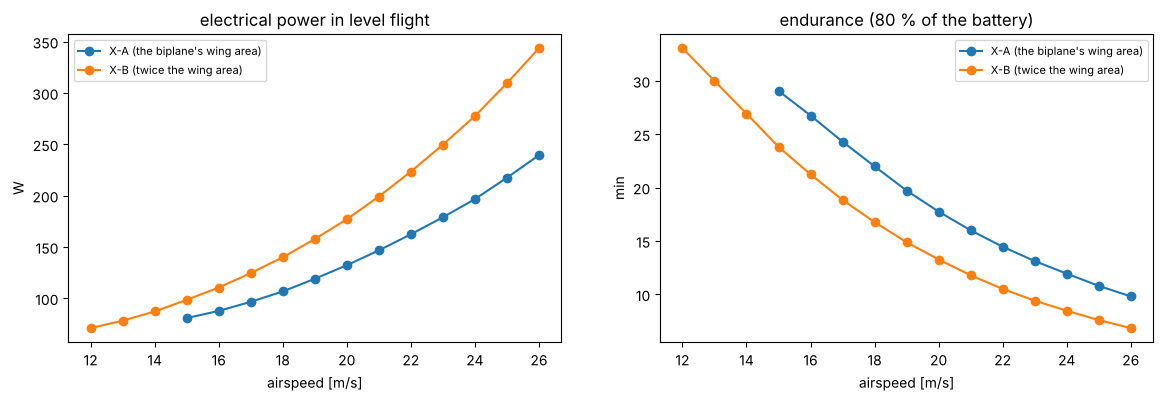

In [6]:
XA = {v: kx.aero(L) for v, L in XL.items()}
XD = {v: kx.drag_buildup(L) for v, L in XL.items()}
BIPLANE = kf.aero()["biplane"]                      # notebook 38's lattice on the flat pair, for the ratio
AER = pd.DataFrame({v: {"CLα vertical [1/rad]": a["CLa"], "CLα / the biplane's": a["CLa"] / BIPLANE["CLa"],
                        "induced k": a["k"], "e (projected span)": a["e"], "AR projected": a["AR_projected"], "x_np [mm]": a["x_np"] * 1000,
                        "Cd0": XD[v]["Cd0"], "CdA [cm²]": XD[v]["CdA_m2"] * 1e4} for v, a in XA.items()}).T
display(AER.round(4))
display(pd.DataFrame({v: {k: x * 1e4 for k, x in d["parts_m2"].items()} for v, d in XD.items()}).T.round(1).rename(columns=lambda c: c + " [cm²]"))
XV = {v: kx.make_vehicle(v) for v in kx.VARIANTS}
CRX = {v: kx.cruise(veh) for v, veh in XV.items()}
for v, c in CRX.items():
    print(v); display(c.round(3))
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for v, c in CRX.items():
    f = c[c["feasible"]]
    ax[0].plot(f.index, f["electrical [W]"], "o-", label=v); ax[1].plot(f.index, f["endurance [min]"], "o-", label=v)
for a_ in ax:
    a_.set_xlabel("airspeed [m/s]"); a_.legend(fontsize=8)
ax[0].set(ylabel="W", title="electrical power in level flight"); ax[1].set(ylabel="min", title="endurance (80 % of the battery)")
plt.show()

### 4b. The panels' section (Zephyr)

What the wing section sees. A panel at 45° must carry its lift at cl = CL_vertical / cos 45°: X-A's panels run at
cl ≈ 0.50 at 16 m/s where the biplane's wings run at 0.38, X-B's at 0.30. From Zephyr's NACA 0012 polar (NeuralFoil,
Re 1.5e5, n_crit 6) and its flap sweep: the section drag at that cl, the elevon that trims the panel with the X's own
static margin (the lattice's neutral point against the CG), that elevon's drag, the section L/D with the trim in,
the margin to cl_max — against the two Kestrels; then over the speed range, and which reflexed section would trim the
X with its elevons level.

the X's static margins (lattice neutral point − CG, in chords): {'X-A': np.float64(0.134), 'X-B': np.float64(0.134)}


,section cl,section cd,trim elevon [deg],Δcd of the trim,cd with the trim,section L/D (trimmed),cl max,margin to stall,cl lost to the elevon
"X-A (0012, panels)",0.5014,0.0133,-9.2704,0.0076,0.0210,23.9096,1.0604,2.1147,-0.5306
"X-B (0012, panels)",0.2966,0.0119,-5.6035,0.0031,0.0150,19.8124,1.0604,3.5752,-0.3207
Kestrel-4Q (0012),0.3800,0.0124,-5.4943,0.0029,0.0154,24.7414,1.0604,2.7904,-0.3144
Kestrel-4Q-2 (NACA 23112 (k2/k1 0.03)),0.3800,0.0157,-0.3556,0.0003,0.0160,23.7377,1.1480,3.0211,-0.0211


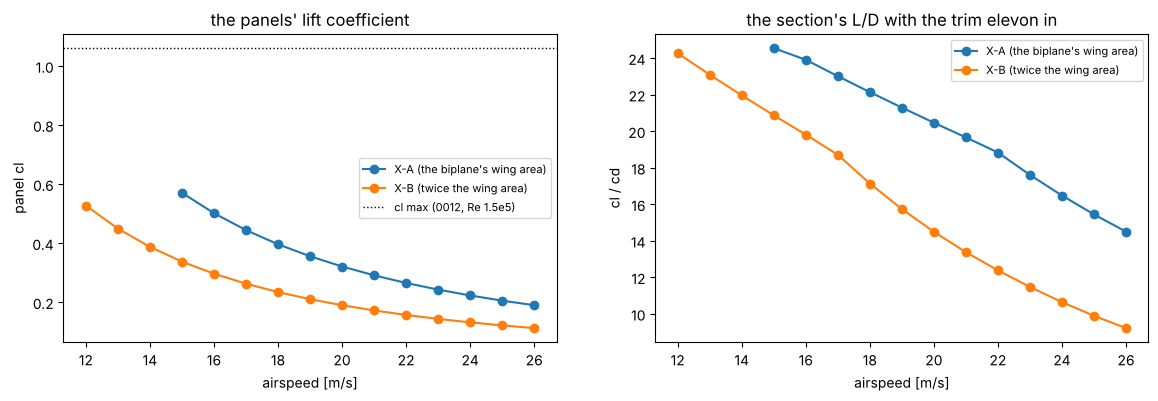

X-A (the biplane's wing area)


,cm needed,cm of the section,elevon [deg],Δcd (elevon),cd cruise,trim drag / section drag
NACA 0012,0.0672,-0.0124,-8.9753,0.0073,0.0124,0.5843
NACA 2412,0.0672,-0.0616,-17.2154,0.0166,0.0115,1.4476
NACA 22112,0.0672,-0.0094,-9.2322,0.0065,0.0128,0.5090
NACA 23112,0.0672,-0.0117,-9.4907,0.0071,0.0134,0.5291
NACA 24112,0.0672,-0.0196,-10.6002,0.0086,0.0137,0.6286
NACA 23112 (k2/k1 0.015),0.0672,0.0038,-7.1582,0.0054,0.0142,0.3786
NACA 23112 (k2/k1 0.02),0.0672,0.0134,-5.8616,0.0042,0.0148,0.2837
NACA 23112 (k2/k1 0.025),0.0672,0.0231,-4.6584,0.0032,0.0152,0.2083
NACA 23112 (k2/k1 0.03),0.0672,0.0328,-3.5309,0.0028,0.0157,0.1761
NACA 24112 (k2/k1 0.06),0.0672,-0.0023,-7.9304,0.0068,0.0145,0.4669


X-B (twice the wing area)


,cm needed,cm of the section,elevon [deg],Δcd (elevon),cd cruise,trim drag / section drag
NACA 0012,0.0397,-0.0124,-5.8823,0.0034,0.0124,0.2733
NACA 2412,0.0397,-0.0616,-13.5481,0.0116,0.0115,1.0097
NACA 22112,0.0397,-0.0094,-5.9273,0.0026,0.0128,0.2013
NACA 23112,0.0397,-0.0117,-6.1890,0.0032,0.0134,0.2364
NACA 24112,0.0397,-0.0196,-7.2485,0.0047,0.0137,0.3395
NACA 23112 (k2/k1 0.015),0.0397,0.0038,-4.0601,0.0020,0.0142,0.1397
NACA 23112 (k2/k1 0.02),0.0397,0.0134,-2.8711,0.0017,0.0148,0.1135
NACA 23112 (k2/k1 0.025),0.0397,0.0231,-1.7610,0.0012,0.0152,0.0787
NACA 23112 (k2/k1 0.03),0.0397,0.0328,-0.7095,0.0006,0.0157,0.0354
NACA 24112 (k2/k1 0.06),0.0397,-0.0023,-4.7998,0.0027,0.0145,0.1891


In [7]:
try:
    import kestrel_section as ksec
    SECT = ksec.table()
    HAVE_ZEPHYR = True
except Exception as exc:
    HAVE_ZEPHYR = False
    print("Zephyr / the section data not available:", type(exc).__name__, exc)
if HAVE_ZEPHYR:
    def section_row(sec, cl, sm):
        p = sec["polar_cruise"]; cl_ = np.array(p["cl"]); i = int(np.argmax(cl_))
        at = lambda key: float(np.interp(cl, cl_[:i + 1], np.array(p[key])[:i + 1]))
        cd, cm = at("cd"), at("cm")
        e = sec["elevon"]
        d_deg = math.degrees((sm * cl - cm) / e["dcm_ddelta_per_rad"])
        dcd = float(np.interp(d_deg, e["deltas_deg"], e["cd_increment"]))
        return {"section cl": cl, "section cd": cd, "trim elevon [deg]": d_deg, "Δcd of the trim": dcd, "cd with the trim": cd + dcd,
                "section L/D (trimmed)": cl / (cd + dcd), "cl max": sec["cruise"]["cl_max"], "margin to stall": sec["cruise"]["cl_max"] / cl,
                "cl lost to the elevon": e["dcl_ddelta_per_rad"] * math.radians(d_deg)}
    S0012 = SECT["NACA 0012"]
    SMX = {v: (XA[v]["x_np"] - XCI[v]["x_cg"]) / XL[v]["chord"] for v in kx.VARIANTS}
    rows = {}
    for v in kx.VARIANTS:
        c16 = CRX[v].loc[16.0]
        rows[f"{v[:3]} (0012, panels)"] = section_row(S0012, float(c16["panel cl"]), SMX[v])
    sm_k = float(KD["neutral_point"]["static_margin"]) if KD else 0.103
    rows["Kestrel-4Q (0012)"] = section_row(S0012, 0.38, sm_k)
    pick = KD["part2"]["options"]["Kestrel-4Q-2"]["section"].replace(" (Zephyr)", "") if KD else "NACA 23112 (k2/k1 0.03)"
    if pick in SECT:
        rows[f"Kestrel-4Q-2 ({pick})"] = section_row(SECT[pick], 0.38, sm_k)
    SEC16 = pd.DataFrame(rows).T
    print("the X's static margins (lattice neutral point − CG, in chords):", {v[:3]: round(s, 3) for v, s in SMX.items()})
    display(SEC16.round(4))
    # over the speed range: the panels' cl and the trimmed section L/D
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    for v in kx.VARIANTS:
        c = CRX[v][CRX[v]["feasible"]]
        rr = [section_row(S0012, float(cl), SMX[v]) for cl in c["panel cl"]]
        ax[0].plot(c.index, c["panel cl"], "o-", label=v); ax[1].plot(c.index, [r["section L/D (trimmed)"] for r in rr], "o-", label=v)
    ax[0].axhline(S0012["cruise"]["cl_max"], color="k", ls=":", lw=1, label="cl max (0012, Re 1.5e5)")
    ax[0].set(xlabel="airspeed [m/s]", ylabel="panel cl", title="the panels' lift coefficient"); ax[1].set(xlabel="airspeed [m/s]", ylabel="cl / cd", title="the section's L/D with the trim elevon in")
    ax[0].legend(fontsize=8); ax[1].legend(fontsize=8); plt.show()
    # which section trims the X with the elevons level: the trim table at the X's margins and panel cl
    for v in kx.VARIANTS:
        print(v)
        display(ksec.trim_table(SECT, static_margin=SMX[v], cl=float(CRX[v].loc[16.0, "panel cl"]))[["cm needed", "cm of the section", "elevon [deg]", "Δcd (elevon)", "cd cruise", "trim drag / section drag"]].astype(float).round(4))

### 4c. The medical capsule in the X's pod

Kestrel carries a removable insulated capsule for medical supplies (72 × 72 × 160 mm, 0.6 L, up to 0.5 kg;
notebook 38 § 11). The biplane stacks the battery, the capsule and the electronics in the 274 mm of pod height
between its wings. The X's pod spans no gap — it is 110 mm square — so the same parts must lie end to end.

In [8]:
CAPX = pd.DataFrame({v: {k: x for k, x in kx.capsule_fit(L).items() if k != "note"} for v, L in XL.items()}).T
display(CAPX)
print(kx.capsule_fit(XL[list(kx.VARIANTS)[0]])["note"])
m_cap = ks.COMPONENTS["capsule"]["shell_kg"] + ks.COMPONENTS["capsule"]["contents_nominal_kg"]
print({v: f"with the nominal capsule: {XCI[v]['mass_kg'] + m_cap:.2f} kg, hover T/W {ks.hover_point(XCI[v]['mass_kg'] + m_cap)['T_W']:.2f}" for v in kx.VARIANTS})

,pod section inside the walls [mm],capsule fits the section,wall left beside the capsule [mm],length needed in line [mm],pod length [mm],fits in line
X-A (the biplane's wing area),98.0,True,13.0,462.0,430.0,False
X-B (twice the wing area),98.0,True,13.0,462.0,430.0,False


the biplane stacks battery, capsule and electronics in its 274 mm of pod height; the X's pod must lay them end to end, and the capsule's contents then sit far from the CG unless the battery slides to meet them


{"X-A (the biplane's wing area)": 'with the nominal capsule: 1.98 kg, hover T/W 2.47', 'X-B (twice the wing area)': 'with the nominal capsule: 2.27 kg, hover T/W 2.15'}


## 5. Standing on the tips

The footprint is the square of the four tips; the wind that tips it (the panels' projected area).

In [9]:
ST = pd.DataFrame({v: {k: x for k, x in kx.stance(L, mass_kg=XCI[v]["mass_kg"], x_cg=XCI[v]["x_cg"]).items() if k != "feet"} for v, L in XL.items()}).T
display(ST.round(2))

,CG height above the ground [m],least tip-over angle [deg],footprint half-width [m],wind that tips it [m/s]
X-A (the biplane's wing area),0.23,60.06,0.39,16.41
X-B (twice the wing area),0.28,62.32,0.53,13.57


## 6. The transitions

Notebook 38's panel model with the X's four panels at 45°: each sees cos 45° of the vertical flow and gives back cos 45°
of its normal force; each is blown by its own rotor; the autopilot trims with the X's own vertical lift slope. The
matrix (both directions, three schedule lengths, still air and a 6 m/s headwind), the nominal episodes, and the back
transition entered slowly.

transitions:   0%|          | 0/24 [00:00<?, ?it/s]

height loss [m]  height gain [m]  pitch error max [deg]  time stalled, free stream [s]  α blown max while stalled [deg]  moment shortfall [s]  \
vehicle                       direction t_tr [s] headwind [m/s]                                                                                                                                                  
X-A (the biplane's wing area) forward   1.5      0.0                        1.20             0.47                   7.32                           0.38                             5.03                   0.0   
                                                 6.0                        0.51             0.20                   5.21                           1.25                            17.44                   0.0   
                                        3.0      0.0                        0.14             0.14                   2.43                           1.18                             8.83                   0.0   
                                                 6.0                        0.49             0.05                   1.86                           2.52                            17.30                   0.0   
                                        5.0      0.0                        0.57             0.13                   1.25                           2.47                            13.89                   0.0   
                                                 6.0                        1.33             0.34                   1.11                           4.19                            18.98                   0.0   
                              back      1.5      0.0                        0.57             0.07                   5.47                           0.84                            58.85                   0.0   
                                                 6.0                        0.57             0.28                   5.47                           0.84                            58.85                   0.0   
                                        3.0      0.0                        1.14             0.17                   2.42                           1.85                            42.75                   0.0   
                                                 6.0                        1.14             0.40                   2.42                           1.85                            42.75                   0.0   
                                        5.0      0.0                        1.69             0.33                   1.00                           4.42                            33.51                   0.0   
                                                 6.0                        1.69             0.63                   1.00                           4.42                            33.51                   0.0   
X-B (twice the wing area)     forward   1.5      0.0                        0.73             0.22                   7.71                           0.33                             4.19                   0.0   
                                                 6.0                        0.53             0.19                   5.29                           1.18                            13.20                   0.0   
                                        3.0      0.0                        0.25             0.10                   2.43                           1.05                             7.55                   0.0   
                                                 6.0                        0.52             0.26                   1.67                           2.39                            13.20                   0.0   
                                        5.0      0.0                        0.65             0.27                   1.15                           2.25                            11.95                   0.0   
                                                 6.0                       

X-A (the biplane's wing area): 12 of 12 pass
X-B (twice the wing area): 10 of 12 pass
   - back 1.5 s, headwind 0 m/s: fails roll holds
   - back 1.5 s, headwind 6 m/s: fails roll holds


,height loss [m],height gain [m],pitch error max [deg],"time stalled, free stream [s]",α blown max while stalled [deg],moment shortfall [s],least pitch margin,peak rotor thrust / T_max,elevon max [deg],roll demand / authority,roll demand / rotors' authority,pass
"X-A, back entered at 16 m/s",1.14447,0.168722,2.422621,1.846,42.745265,0.0,0.766277,0.476547,5.694914,0.569395,2.101771,True
"X-A, back entered at 13 m/s",4.340581,1.355033,1.877057,3.0,38.70806,0.0,0.742671,0.901102,6.272251,0.514724,1.443723,False
"X-A, back entered at 11 m/s",6.075481,1.899072,2.105878,3.0,59.548253,0.0,0.742139,0.990881,6.286207,0.474598,1.237903,False
"X-B, back entered at 16 m/s",0.53493,2.528127,2.661111,1.312,64.231759,0.0,0.631442,0.577465,9.114645,0.859827,6.906869,True
"X-B, back entered at 13 m/s",1.195876,0.147885,2.544344,1.78,42.673506,0.0,0.63578,0.561655,9.009255,0.84511,4.748484,True
"X-B, back entered at 11 m/s",3.889656,1.130524,2.092292,3.0,29.784005,0.0,0.642601,0.698946,8.826784,0.448167,3.704967,False


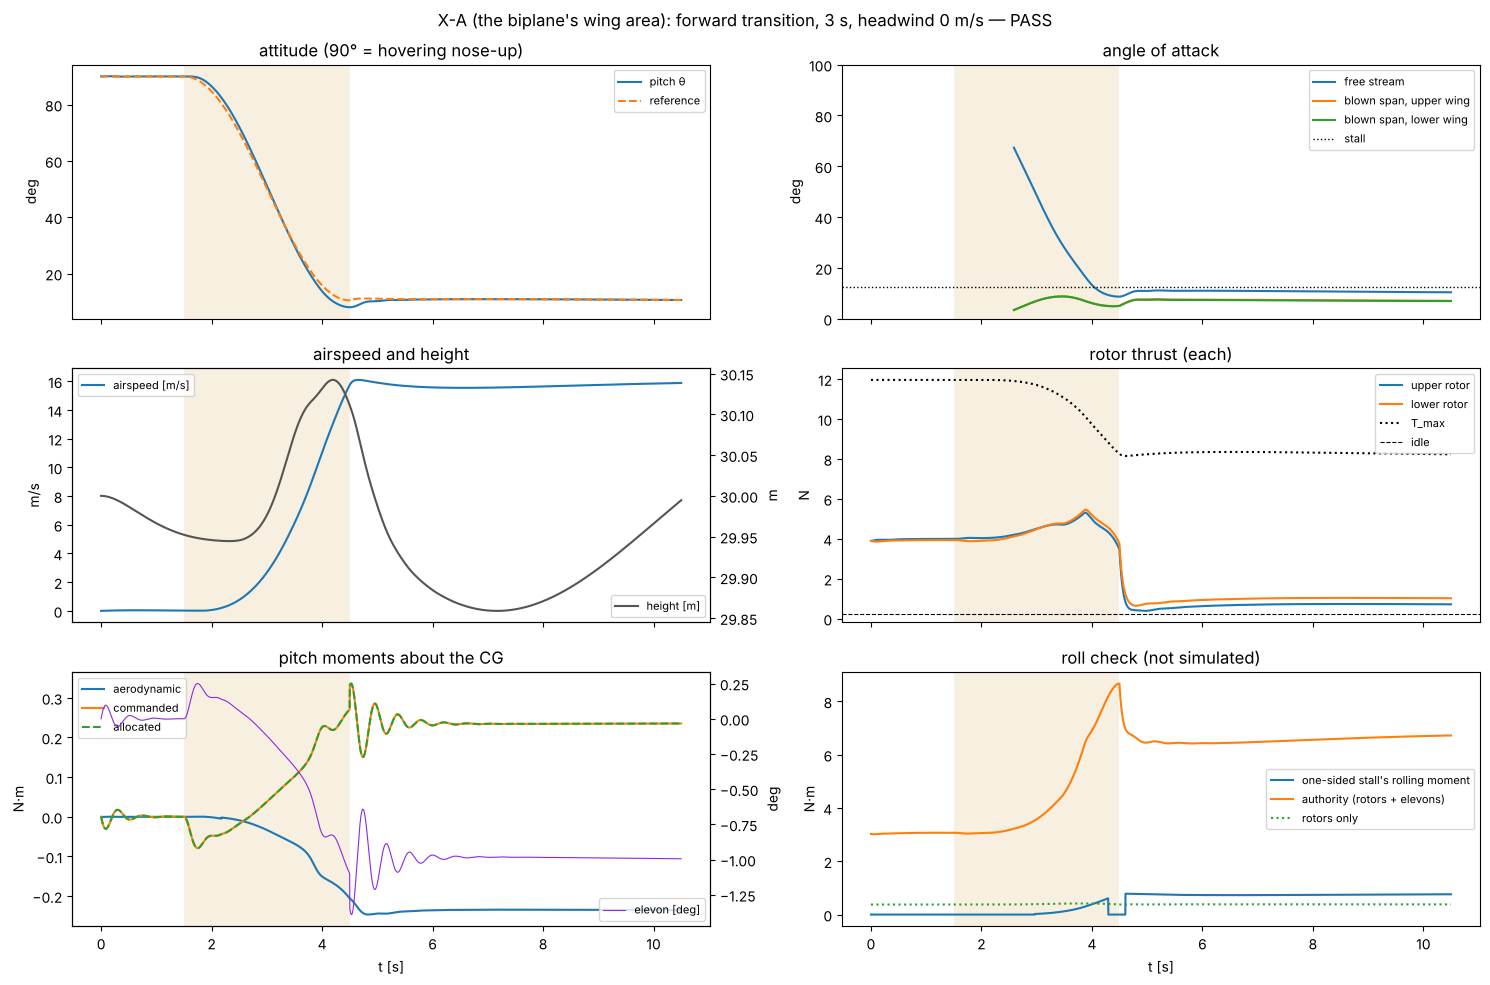

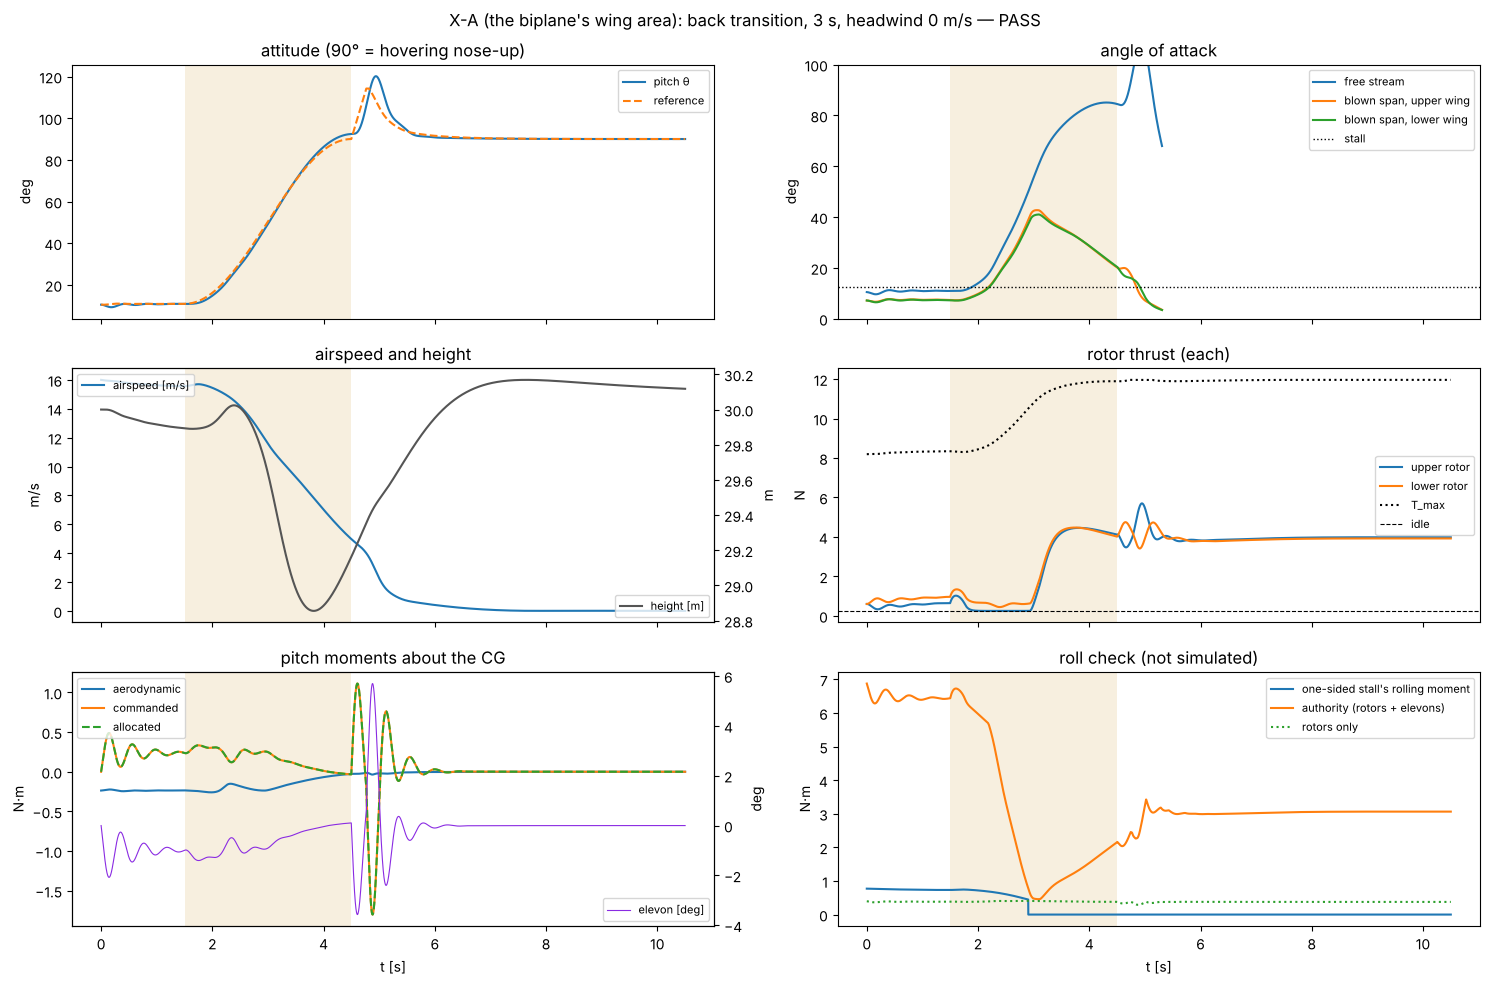

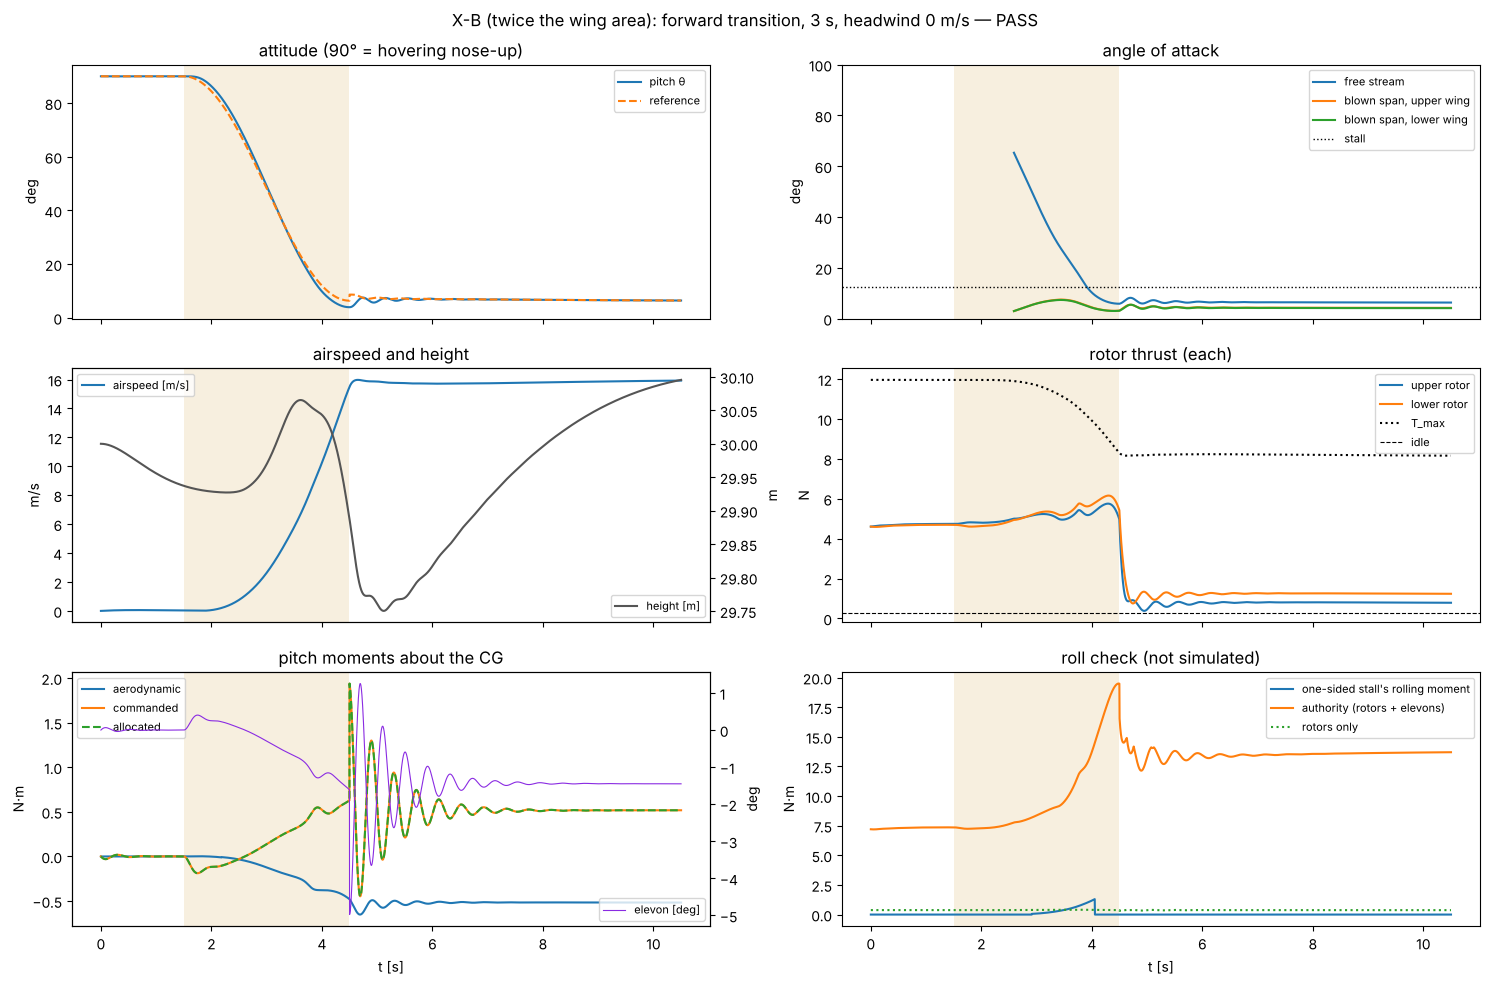

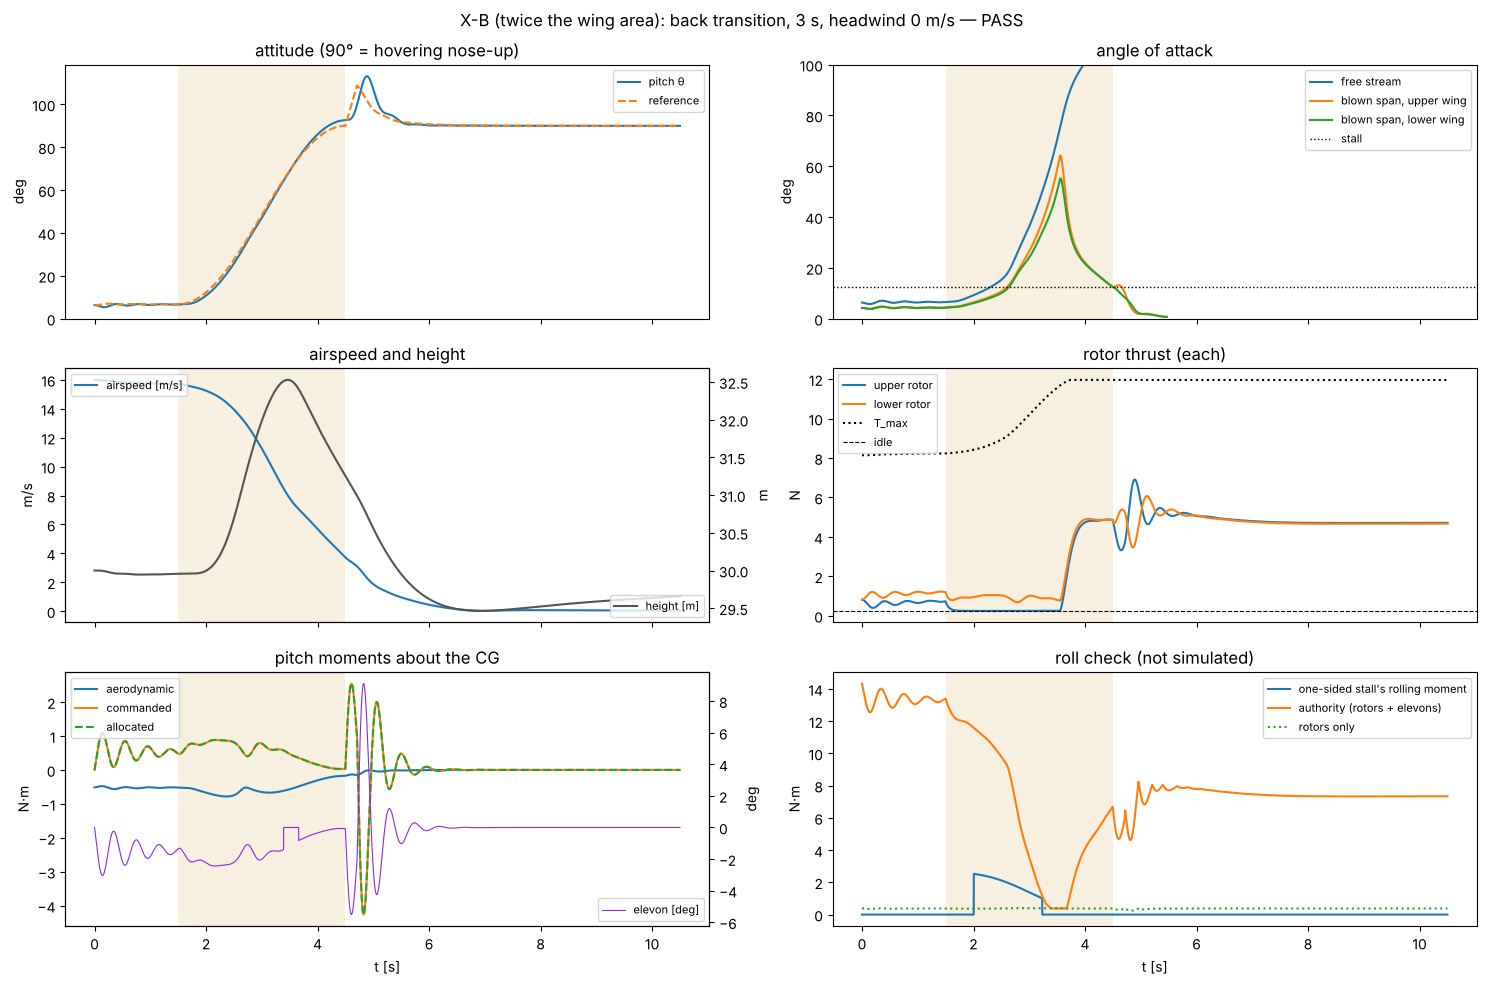

In [10]:
durs = (1.5, 3.0) if QUICK else (1.5, 3.0, 5.0)
MATX, EPSX = kt.matrix(XV, durations=durs, headwinds=(0.0, 6.0), progress=True)
cols = ["height loss [m]", "height gain [m]", "pitch error max [deg]", "time stalled, free stream [s]", "α blown max while stalled [deg]",
        "moment shortfall [s]", "least pitch margin", "peak rotor thrust / T_max", "elevon max [deg]", "roll demand / authority",
        "roll demand / rotors' authority", "pass"]
display(MATX[cols].astype({c: float for c in cols if c != "pass"}).round(2))
VERX = kt.verdict(MATX)
for k, v in VERX.items():
    print(f"{k}: {v['passes']} of {v['of']} pass" + ("".join(f"\n   - {w}" for w in v["failures"]) if v["failures"] else ""))
MATX.to_csv(OUT / "transition_matrix.csv")
SLOW = pd.DataFrame({f"{v[:3]}, back entered at {ve:g} m/s": kt.simulate(veh, "back", t_tr=3.0, V_entry=ve).metrics for v, veh in XV.items() for ve in (16.0, 13.0, 11.0)}).T
display(SLOW[cols])
for v, veh in XV.items():
    kd.episode_figure(EPSX[(v, "forward", 3.0, 0.0)], veh); plt.show()
    kd.episode_figure(EPSX[(v, "back", 3.0, 0.0)], veh); plt.show()

## 7. Against Kestrel-4Q and Kestrel-4Q-2

In [11]:
rows = {}
for v in kx.VARIANTS:
    L, veh, c = XL[v], XV[v], CRX[v]
    feas = c[c["feasible"]]; c16 = c.loc[16.0]
    hx = kc.hover_authority(mass_kg=veh.mass, cg={"x_cg": veh.x_cg, "y_cg": 0.0, "z_cg": veh.z_cg}, inertia=XCI[v]["I"], L=L)
    rows[v] = {"mass [kg]": veh.mass, "wing area [m²]": L["S_ref"], "projected span [m]": L["span_projected"], "CLα vertical": XA[v]["CLa"], "induced k": XA[v]["k"],
               "Cd0": veh.pol.cd0, "CdA [cm²]": veh.pol.cd0 * L["S_ref"] * 1e4, "α at 16 m/s [deg]": c16.get("α [deg]", np.nan), "panel cl at 16 m/s": c16["panel cl"],
               "power at 16 m/s [W]": c16.get("electrical [W]", np.nan), "endurance best [min]": feas["endurance [min]"].max(), "at [m/s]": feas["endurance [min]"].idxmax(),
               "hover pitch [rad/s²]": hx.iloc[1]["angular acceleration [rad/s²]"], "hover heading [rad/s²]": hx.iloc[0]["angular acceleration [rad/s²]"],
               "spar OD [mm]": SPAR.loc[v, "spar OD [mm]"], "tip-over [deg]": ST.loc[v, "least tip-over angle [deg]"], "wind that tips it [m/s]": ST.loc[v, "wind that tips it [m/s]"],
               "transitions passed": f"{VERX[v]['passes']} of {VERX[v]['of']}", "bracing": "none"}
if KD:
    o = KD["part2"]["options"]
    for name in ("Kestrel-4Q (Part I)", "Kestrel-4Q-2"):
        r = o[name]
        rows[name] = {"mass [kg]": r["mass [kg]"], "wing area [m²]": 0.28, "projected span [m]": 1.0, "CLα vertical": BIPLANE["CLa"], "induced k": BIPLANE["k"], "Cd0": r["Cd0"],
                      "CdA [cm²]": r["Cd0"] * 0.28 * 1e4, "power at 16 m/s [W]": r["power at 16 m/s [W]"], "endurance best [min]": r["endurance best [min]"],
                      "hover pitch [rad/s²]": r["hover pitch [rad/s²]"], "transitions passed": r["transitions passed"], "bracing": r["bracing"] + (", faired" if r["struts"] == "faired" else ", round")}
    g = KD["ground"]
    rows["Kestrel-4Q (Part I)"].update({"tip-over [deg]": g["least tip-over angle [deg]"], "wind that tips it [m/s]": g["wind that tips it, broadside [m/s]"], "hover heading [rad/s²]": 2.35})
CMP = pd.DataFrame(rows).T
display(CMP)
CMP.to_csv(OUT / "xwing_vs_kestrel.csv")

,mass [kg],wing area [m²],projected span [m],CLα vertical,induced k,Cd0,CdA [cm²],α at 16 m/s [deg],panel cl at 16 m/s,power at 16 m/s [W],endurance best [min],at [m/s],hover pitch [rad/s²],hover heading [rad/s²],spar OD [mm],tip-over [deg],wind that tips it [m/s],transitions passed,bracing
X-A (the biplane's wing area),1.587391,0.28,0.784889,1.879121,0.145314,0.034411,96.352031,10.811065,0.501436,87.648871,29.058521,15.0,67.000348,1.810702,9.0,60.063308,16.413303,12 of 12,none
X-B (twice the wing area),1.877831,0.56,1.067731,1.883926,0.143872,0.03032,169.793361,6.378255,0.296591,110.429588,33.063785,12.0,50.555118,0.916246,13.5,62.324043,13.573871,10 of 12,none
Kestrel-4Q (Part I),1.686206,0.28,1.0,4.07843,0.059916,0.066549,186.336353,NaN,NaN,110.215621,40.193712,NaN,94.992838,2.35,NaN,39.337117,8.90529,11 of 12,"x, round"
Kestrel-4Q-2,1.651145,0.28,1.0,4.07843,0.059916,0.02574,72.071783,NaN,NaN,59.122378,57.036213,NaN,88.384113,NaN,NaN,NaN,NaN,8 of 12 (6 of 6 back with the 13 m/s entry),"posts, faired"


### 7b. Drag, power, maximum speed and manoeuvrability against airspeed — all four

Kestrel-4Q-1 and 4Q-2 rebuilt here from the same modules (4Q-2 as elevons + faired posts, no X; the reflexed section's
small change is left out of this comparison), the two X-wings as above. The drag split into parasite and induced, the
rotors' full thrust against the drag (the thrust-limited maximum speed), the power; then pitch, roll, yaw and the turn
in horizontal flight.

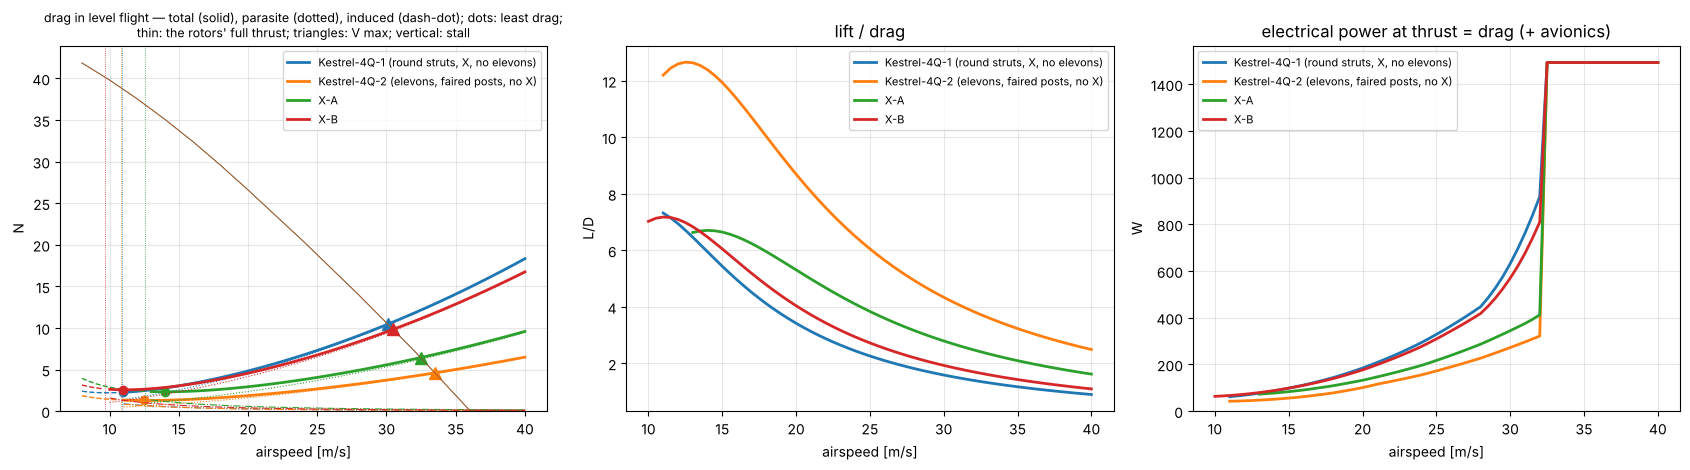

,V stall [m/s],V of least drag [m/s],least drag [N],best L/D,drag at 16 m/s [N],parasite at 16 [N],induced at 16 [N],power at 16 m/s [W],least power [W],V of least power [m/s],"V max, thrust = drag [m/s]",full thrust at 16 m/s [N],thrust / drag at 16 m/s,power at V max [W]
"Kestrel-4Q-1 (round struts, X, no elevons)",10.91,11.0,2.26,7.32,3.34,2.92,0.41,111.44,61.66,11.0,30.09,32.42,9.72,642.74
"Kestrel-4Q-2 (elevons, faired posts, no X)",10.80,12.5,1.28,12.66,1.43,1.03,0.40,61.79,42.33,11.0,33.49,32.42,22.73,1493.00
X-A,12.59,14.0,2.32,6.71,2.40,1.51,0.89,90.45,72.75,13.0,32.46,32.42,13.50,1493.00
X-B,9.68,11.0,2.56,7.18,3.28,2.66,0.62,110.17,63.18,10.0,30.47,32.42,9.88,616.08


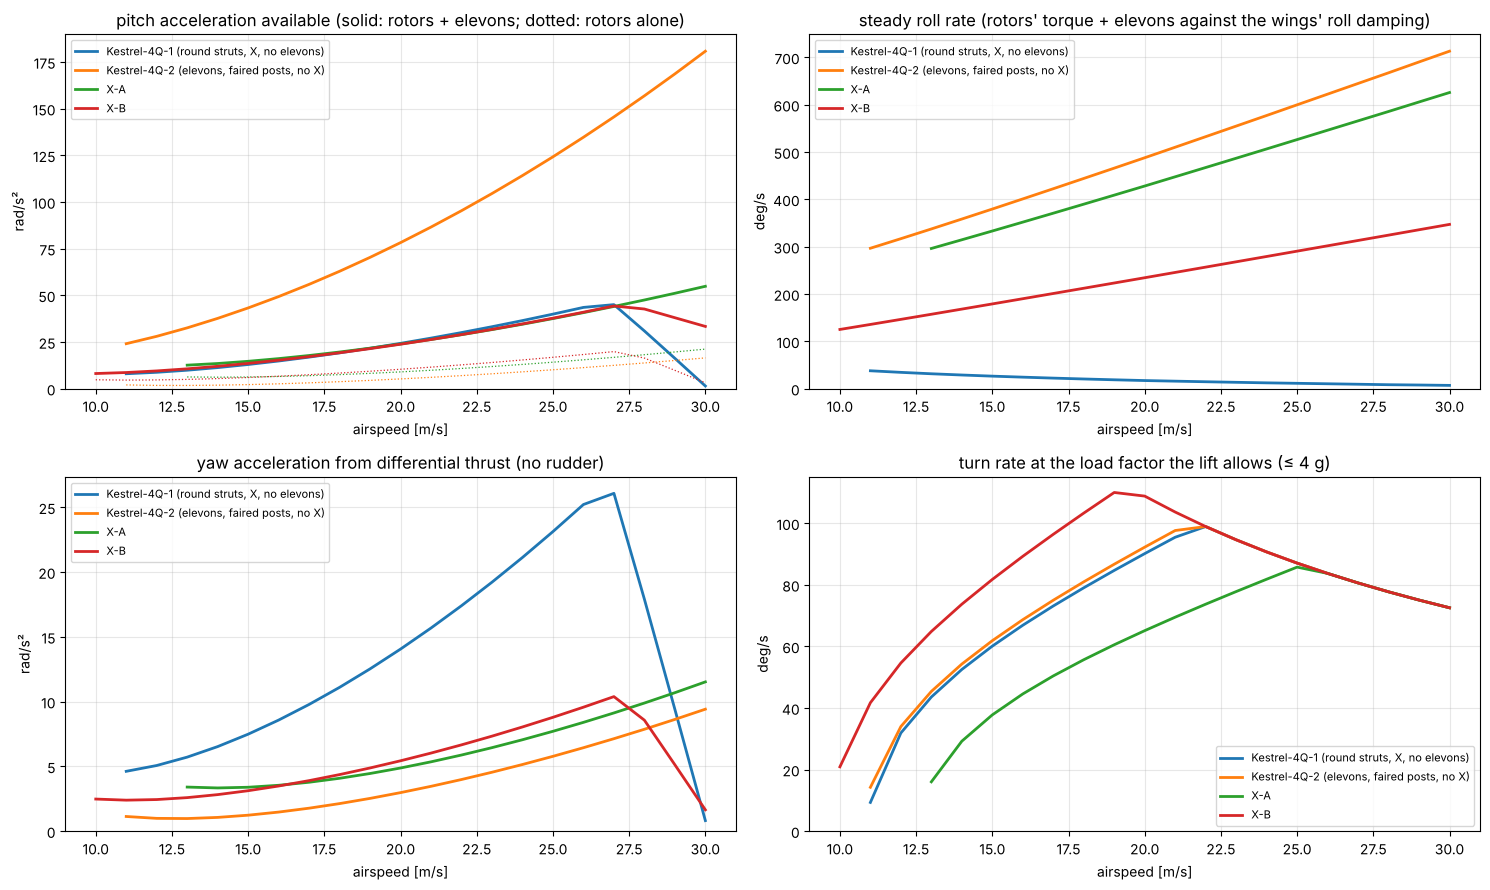

Kestrel-4Q-1 (round struts, X, no elevons)


,CL,thrust per rotor [N],ΔT available [N],pitch: rotors [rad/s²],pitch: elevons [rad/s²],pitch: total [rad/s²],yaw: rotors [rad/s²],roll: rotors' torque [N·m],roll: elevons [N·m],roll acceleration [rad/s²],steady roll rate [deg/s],load factor available,turn rate [deg/s],turn radius [m]
V [m/s],,,,,,,,,,,,,,
14.0,0.49,0.69,0.44,11.26,0.0,11.26,6.52,0.41,0.0,3.85,28.75,1.65,52.50,15.28
16.0,0.38,0.83,0.58,14.79,0.0,14.79,8.57,0.39,0.0,3.71,24.21,2.15,66.86,13.71
20.0,0.24,1.21,0.96,24.25,0.0,24.25,14.05,0.35,0.0,3.26,17.03,3.36,90.13,12.71
25.0,0.15,1.83,1.58,39.90,0.0,39.90,23.12,0.28,0.0,2.68,11.20,4.00,87.05,16.46


Kestrel-4Q-2 (elevons, faired posts, no X)


,CL,thrust per rotor [N],ΔT available [N],pitch: rotors [rad/s²],pitch: elevons [rad/s²],pitch: total [rad/s²],yaw: rotors [rad/s²],roll: rotors' torque [N·m],roll: elevons [N·m],roll acceleration [rad/s²],steady roll rate [deg/s],load factor available,turn rate [deg/s],turn radius [m]
V [m/s],,,,,,,,,,,,,,
14.0,0.48,0.33,0.08,1.85,35.78,37.63,1.06,0.41,4.69,45.13,358.32,1.68,54.26,14.78
16.0,0.37,0.36,0.11,2.57,46.73,49.30,1.47,0.39,6.13,57.70,400.86,2.20,68.67,13.35
20.0,0.24,0.47,0.22,5.19,73.02,78.21,2.97,0.35,9.58,87.77,487.85,3.43,92.22,12.43
25.0,0.15,0.67,0.42,10.09,114.09,124.18,5.77,0.28,14.97,134.87,599.72,4.00,87.05,16.46


X-A


,CL,thrust per rotor [N],ΔT available [N],pitch: rotors [rad/s²],pitch: elevons [rad/s²],pitch: total [rad/s²],yaw: rotors [rad/s²],roll: rotors' torque [N·m],roll: elevons [N·m],roll acceleration [rad/s²],steady roll rate [deg/s],load factor available,turn rate [deg/s],turn radius [m]
V [m/s],,,,,,,,,,,,,,
14.0,0.46,0.58,0.33,6.12,7.33,13.45,3.33,0.41,4.68,39.45,314.50,1.24,29.21,27.46
16.0,0.35,0.60,0.35,6.50,9.57,16.07,3.54,0.39,6.11,50.44,351.81,1.62,44.55,20.58
20.0,0.23,0.73,0.48,8.95,14.95,23.91,4.87,0.35,9.54,76.72,428.11,2.52,65.11,17.60
25.0,0.15,1.01,0.76,14.16,23.36,37.52,7.71,0.28,14.91,117.89,526.25,3.94,85.74,16.71


X-B


,CL,thrust per rotor [N],ΔT available [N],pitch: rotors [rad/s²],pitch: elevons [rad/s²],pitch: total [rad/s²],yaw: rotors [rad/s²],roll: rotors' torque [N·m],roll: elevons [N·m],roll acceleration [rad/s²],steady roll rate [deg/s],load factor available,turn rate [deg/s],turn radius [m]
V [m/s],,,,,,,,,,,,,,
14.0,0.27,0.71,0.46,5.38,6.57,11.95,2.82,0.41,9.67,32.99,168.01,2.09,73.70,10.88
16.0,0.21,0.82,0.57,6.65,8.58,15.23,3.48,0.39,12.63,42.63,189.96,2.73,89.25,10.27
20.0,0.13,1.14,0.89,10.37,13.41,23.78,5.43,0.35,19.74,65.72,234.31,4.00,108.81,10.53
25.0,0.09,1.69,1.44,16.78,20.96,37.73,8.79,0.28,30.84,101.85,290.49,4.00,87.05,16.46


In [12]:
P2 = kestrel.resolve(dict(elevons=True, strut_fairing=True, bracing="posts"))
FOUR = {"Kestrel-4Q-1 (round struts, X, no elevons)": kt.make_vehicle(elevons=False, name="4Q-1"),
        "Kestrel-4Q-2 (elevons, faired posts, no X)": kt.make_vehicle(P2, faired=True, name="4Q-2")}
FOUR.update({v[:3]: XV[v] for v in kx.VARIANTS})
fig, axs = plt.subplots(1, 3, figsize=(17, 4.8))
DRAG4 = kd.drag_vs_speed(FOUR, speeds=np.arange(8.0, 40.5, 0.5), axs=axs); plt.tight_layout(); plt.show()
display(DRAG4.round(2))
fig, axs = plt.subplots(2, 2, figsize=(15, 9))
MANV4 = kd.manoeuvrability_figure(FOUR, axs=axs); plt.tight_layout(); plt.show()
for k, df in MANV4.items():
    print(k); display(df.loc[[v for v in (14.0, 16.0, 20.0, 25.0) if v in df.index]].round(2))
DRAG4.to_csv(OUT / "drag_vs_speed.csv")

## 8. Findings

**Lift.** A panel at 45° gives back cos 45° of its normal force vertically and sees cos 45° of the vertical flow: the
lattice puts the X's vertical lift slope at **1.88 /rad against the biplane's 4.08** (0.46 ×) with the same area and
motors. So X-A (the biplane's 0.28 m²) flies 16 m/s at 10.8° with its panels at cl 0.50 and stalls at 12.6 m/s —
**1.27 × the stall** where the biplane has 1.47 ×; X-B buys its margin (stall 9.7 m/s, 6.4° at the cruise) with twice
the area, not better geometry — 0.29 kg of spars and panels more (1.88 kg against X-A's 1.59 and the biplane's 1.65–1.69).

**Drag, power, speed.** No truss and no fin: X-A's Cd0 0.034 (96 cm²) sits between the round-strut biplane (0.067,
186 cm²) and the faired 4Q-2 (0.026, 72 cm²); X-B's 0.030 is on twice the area (170 cm²). At 16 m/s: **X-A 88 W, X-B
110 W, 4Q 110 W, 4Q-2 59 W**; the best endurance 29 min at 15 m/s, 33 at 12, 40, **57**. The thrust-limited maximum
speed is within 3 m/s for all four (30–33.5 m/s): the 9×6's pitch speed, not the airframe, sets it.

**Transitions.** In the same panel model X-A passes **12 of 12** at the cruise entry and X-B **10 of 12** (the 1.5 s
back transition fails on roll: the big 45° panels' one-sided stall against the rotors' torque). The X's rule is the
biplane's inverted: the X must enter the back transition **fast** — X-A entered at 13 m/s (1.03 × its stall) sinks
4.3 m, at 11 m/s 6.1 m — where 4Q-2 must enter slowly (≤ 13 m/s) or balloon. In cruise the elevons give X-A the
biplane's roll rate (350°/s against 4Q-2's 400) but a third of its pitch (16 against 49 rad/s²), and at the lift
limit X-A turns at 45°/s in a 21 m radius (4Q-2: 69°/s, 13 m; X-B, on its area: 89°/s, 10 m).

**The hover and the ground.** Pitch authority 67 rad/s² (X-A) and 51 (X-B) against the biplane's 95; the heading
1.8 and 0.9 against 2.35 — the same weak axis. Standing on its four tips the X tips over at 60° and in a 16 m/s wind
(the biplane: 39°, 9 m/s broadside): the better landing gear by far.

**The section (Zephyr).** With NACA 0012 and a 0.134 static margin X-A's trim costs −9.3° of elevon and half its
section lift at the cruise cl of 0.50 (X-B: −5.6°); the reflexed NACA 23112 (k₂/k₁ 0.03) trims X-A at −3.5° and
X-B at −0.7°, the same pick as the biplane's for the same reason.

**The medical capsule.** The 72 × 72 × 160 mm capsule fits the X's pod section (98 mm inside the walls, 13 mm to
spare) but not in line with the battery and the electronics: 462 mm needed in a 430 mm pod. The biplane stacks the
three in 274 mm of pod height; the X must lengthen its pod by ~40 mm or carry the contents far from the CG. Carried,
the nominal capsule puts X-A at 1.98 kg (hover T/W 2.47) and X-B at 2.27 kg (2.15).

**Which one for what.** **X-A** is the simplest, lightest and most robust airframe here — no truss, no fin, four spars,
the best stance on the ground, every transition passed at the cruise entry — for short sorties that are mostly hover
and a small payload; it pays with a cruise 1.27 × its stall, 50 % more power than 4Q-2 and a pod that needs
lengthening for the capsule. **X-B** buys the stall margin and the tightest turn with area, and gives up the X's
lightness (1.88 kg, 110 W) without reaching the biplane's endurance; it is the one to pass over. **Kestrel-4Q-2** is
the aircraft for the medical mission — 57 min against 29–33, 59 W against 88–110, the capsule stacked on the axis,
the strongest pitch in the hover — on two conditions it must keep: the faired, braced truss and the slow entry into
the back transition. Every number is the lattice, Boreas and the panel model; the X-wing has no CFD yet (notebook 40
needs a CAD class for it first) and its roll–yaw coupling through 45° panels waits for the 6-DOF run.

In [13]:
def plain(x):
    if isinstance(x, (np.floating, float)):
        return None if not np.isfinite(x) else float(x)
    if isinstance(x, (np.integer,)):
        return int(x)
    if isinstance(x, (np.bool_,)):
        return bool(x)
    return x
rows_ = lambda df: {" | ".join(map(str, k)) if isinstance(k, tuple) else str(k): {kk: plain(vv) for kk, vv in r.items()} for k, r in df.T.to_dict().items()}
DESIGN = {"source": "39_xwing", "variants": kx.VARIANTS, "layout": {v: {k: plain(x) for k, x in L.items() if isinstance(x, (int, float))} for v, L in XL.items()},
          "mass": {v: {k: plain(x) for k, x in c.items() if k != "I"} for v, c in XCI.items()}, "aero": {v: {k: plain(x) for k, x in a.items() if k != "note"} for v, a in XA.items()},
          "spars": rows_(SPAR), "transitions": rows_(MATX[cols]), "verdict": VERX, "slow_entry": rows_(SLOW[cols]), "comparison": rows_(CMP.astype(object)),
          "drag_vs_speed": rows_(DRAG4), "manoeuvrability_at_16": {k: {kk: plain(vv) for kk, vv in df.loc[16.0].items()} for k, df in MANV4.items() if 16.0 in df.index}}
target = OUT / "xwing_design.json" if DEBUG else Path("designs/data/xwing_design.json")
target.write_text(json.dumps(DESIGN, indent=1, default=str))
print("written", target)

written designs/data/xwing_design.json
